> **Note (November 2026): this notebook is the original exploratory version, and its evaluation leaks future information.**
>
> It predicts the same day's close from that day's high and low, the 20-day trend includes the close being predicted, the train/test split is random rather than by date, and the outlier capping and skew transform are fitted on the whole dataset. That is why it reports R² near 0.9998.
>
> The leakage-free pipeline is in `sideproject.py` (next-day returns, chronological split, walk-forward cross-validation, baselines). See the README for its results.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")
sns.set_style("darkgrid", {"grid.color": ".6",
						"grid.linestyle": ":"})

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Lasso

from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV

In [2]:
# read dataset using pandas function
# use parse_dates argument to change datetime dtype
dataset = pd.read_csv("BTC.csv", parse_dates=["date"])

In [3]:
# information about the dataset
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5503 entries, 0 to 5502
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   ticker  5503 non-null   object        
 1   date    5503 non-null   datetime64[ns]
 2   open    5503 non-null   float64       
 3   high    5503 non-null   float64       
 4   low     5503 non-null   float64       
 5   close   5503 non-null   float64       
dtypes: datetime64[ns](1), float64(4), object(1)
memory usage: 258.1+ KB


In [4]:
# Missing Values/Null Values Count
dataset.isna().sum().sort_values(ascending=False)

ticker    0
date      0
open      0
high      0
low       0
close     0
dtype: int64

In [5]:
# drop ticker column as it's not needed for prediction
dataset.drop("ticker", axis=1, inplace=True)

In [6]:
# set the index to date column
dataset.set_index("date", inplace=True)

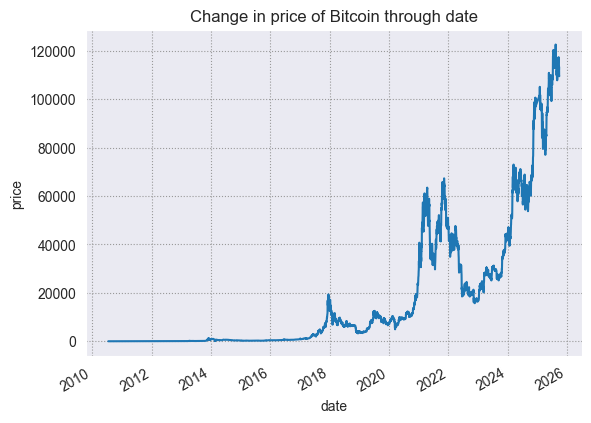

In [7]:
# plot price of bitcoin for each increasing day
dataset["close"].plot()
plt.title("Change in price of Bitcoin through date")
plt.xlabel("date")
plt.ylabel("price")
plt.show()

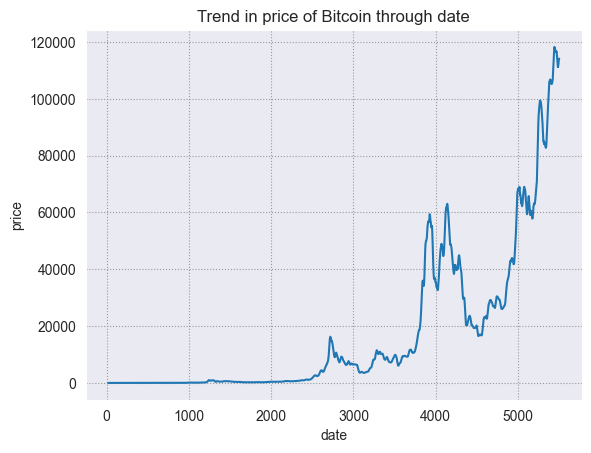

In [8]:
# apply rolling mean with window size of 20
dataset["price_trend"] = dataset["close"]\
	.rolling(window=20).mean()

# reset the index to date column
dataset.reset_index("date", inplace=True)

# since we have used rolling method
# for 20 rows first 19 rows will be NAN
dataset["price_trend"].loc[20:].plot()

# set title of the chart
plt.title("Trend in price of Bitcoin through date")

# set x_label of the plot
plt.xlabel("date")
plt.ylabel("price")
plt.show()

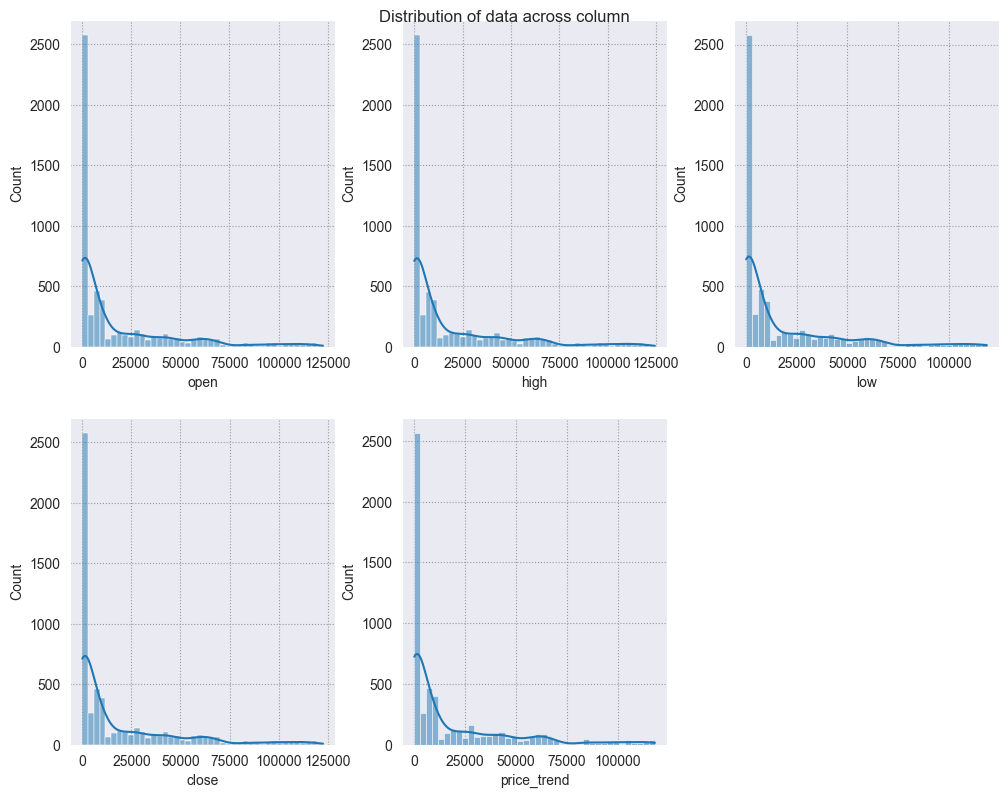

In [9]:
fig = plt.figure(figsize=(10, 8))

# suptitle of the graph
fig.suptitle('Distribution of data across column')
temp = dataset.drop("date", axis=1).columns.tolist()
for i, item in enumerate(temp):
	plt.subplot(2, 3, i+1)
	sns.histplot(data=dataset, x=item, kde=True)
plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=2.0)
plt.show()

In [10]:
# skewness along the index axis
print(dataset.drop("date", axis=1).skew(axis=0, skipna=True))

open           1.893902
high           1.874976
low            1.916197
close          1.892733
price_trend    1.883456
dtype: float64


In [11]:
# apply square root transformation on the most skewed columns
# Applying transformation to reduce skewness if needed
skewed_columns = dataset.drop("date", axis=1).skew(axis=0, skipna=True)
# Transform columns with skewness > 1
for col in skewed_columns[skewed_columns > 1].index:
    dataset[col] = dataset[col].apply(lambda x: np.sqrt(x) if x > 0 else 0)

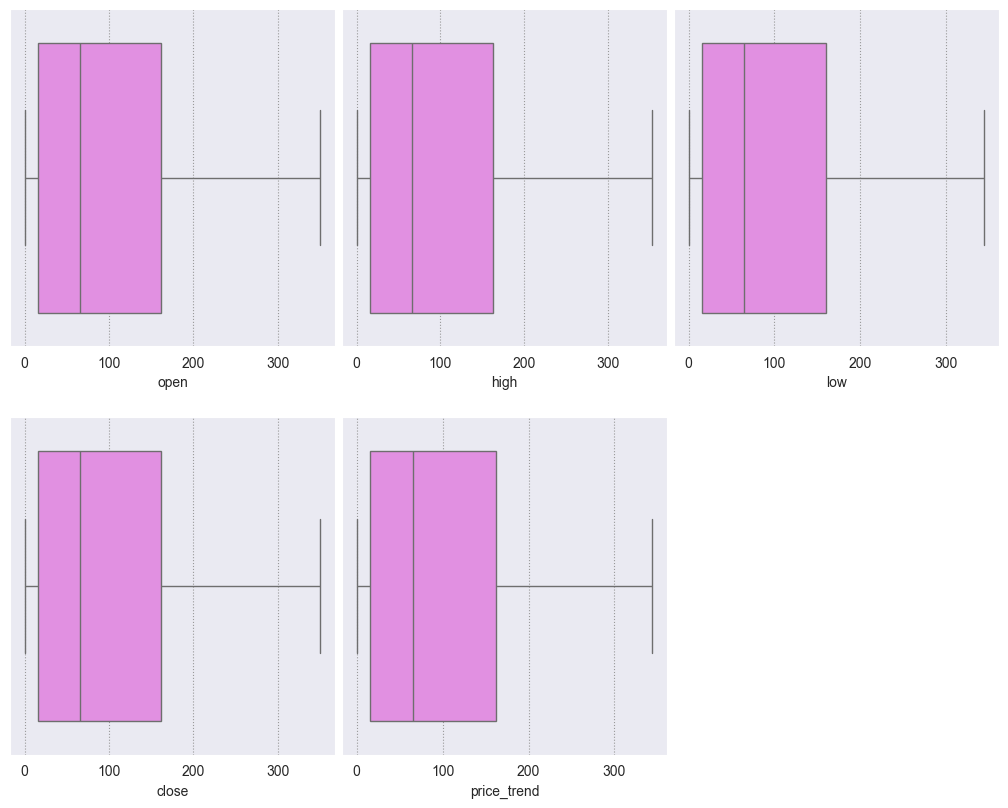

In [12]:
fig = plt.figure(figsize=(10, 8))
temp = dataset.drop("date", axis=1).columns.tolist()
for i, item in enumerate(temp):
	plt.subplot(2, 3, i+1)
	sns.boxplot(data=dataset, x=item, color='violet')
plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=2.0)
plt.show()

In [13]:
def outlier_removal(column):
	# Capping the outlier rows with Percentiles
	upper_limit = column.quantile(.95)
	# set upper limit to 95percentile
	lower_limit = column.quantile(.05)
	# set lower limit to 5 percentile
	column.loc[(column > upper_limit)] = upper_limit
	column.loc[(column < lower_limit)] = lower_limit
	return column

In [14]:
# Normalize outliers in columns except date
dataset[['open', 'high', 'low', 'close']] = dataset[['open', 'high', 'low', 'close']].apply(outlier_removal)

In [15]:
# select the features and target variable
X = dataset.drop(['date', 'close'], axis=1)

y = dataset['close']
# dividing dataset into train test
x_train, x_test, y_train, y_test = train_test_split(X, y,
									test_size=0.2)

In [16]:
# Create an instance of the StandardScaler
scaler = StandardScaler()

# Fit the StandardScaler on the training dataset
scaler.fit(x_train)

# Transform the training dataset
# using the StandardScaler
x_train_scaled = scaler.transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [17]:
# Impute missing values using SimpleImputer
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='mean') # Replace NaNs with the mean of each column

# Fit and transform the imputer on the scaled training data
x_train_scaled = imputer.fit_transform(x_train_scaled)

# Transform the scaled test data using the trained imputer
x_test_scaled = imputer.transform(x_test_scaled)

# Create a PolynomialFeatures object of degree 2
poly = PolynomialFeatures(degree=2)

# Create a Lasso object
lasso = Lasso()

# Define a dictionary of parameter
# values to search over
param_grid = {'lasso__alpha': [1e-4, 1e-3, 1e-2,
							1e-1, 1, 5, 10,
							20, 30, 40]}

# Create a pipeline that first applies
# polynomial features and then applies Lasso regression
pipeline = make_pipeline(poly, lasso)

# Create a GridSearchCV object with
# the pipeline and parameter grid
lasso_grid_search = GridSearchCV(pipeline,
								param_grid,
								scoring='r2', cv=3)

# Fit the GridSearchCV object to the training data
lasso_grid_search.fit(x_train_scaled, y_train)

# Predict the target variable using
# the fitted model and the test data
y_pred = lasso_grid_search.predict(x_train_scaled)

# Compute the R-squared of the fitted model on the train data
r2 = r2_score(y_train, y_pred)

# Print the R-squared
print("R-squared: ", r2)

# Print the best parameter values and score
print('Best parameter values: ',
	lasso_grid_search.best_params_)
print('Best score: ',
	lasso_grid_search.best_score_)

R-squared:  0.9997842209504819
Best parameter values:  {'lasso__alpha': 0.001}
Best score:  0.9997810003441486


In [18]:
# Instantiate param grid for which to search
param_grid = {'n_estimators': [50, 80, 100],
			'max_depth': [3, 5, 7]}

# create instance of the Randomforest regressor
rf = RandomForestRegressor()

# Define Gridsearch with random forest
# object parameter grid scoring and cv
rf_grid_search = GridSearchCV(rf, param_grid, scoring='r2', cv=2)

# Fit the GridSearchCV object to the training data
rf_grid_search.fit(x_train_scaled, y_train)

# Print the best parameter values and score
print('Best parameter values: ', rf_grid_search.best_params_)
print('Best score: ', rf_grid_search.best_score_)

Best parameter values:  {'max_depth': 7, 'n_estimators': 80}
Best score:  0.9998410581814623


In [19]:
# Compute the R-squared of the
# fitted model on the test data
r2 = r2_score(y_test,
			rf_grid_search.predict(x_test_scaled))

# Print the R-squared
print("R-squared:", r2)

R-squared: 0.9998356590939865


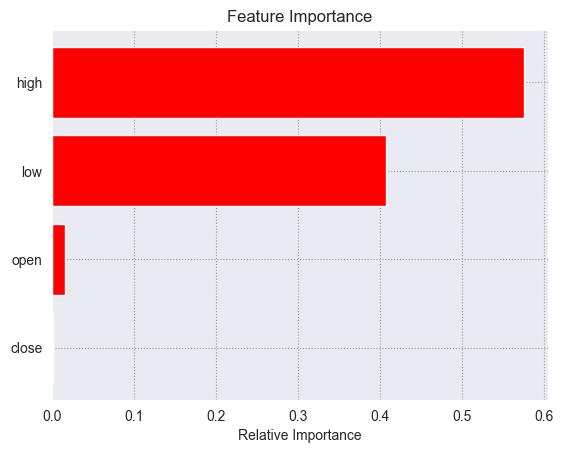

In [20]:
features = dataset.drop("date", axis=1).columns

# store the importance of the feature
importances = rf_grid_search.best_estimator_.feature_importances_

indices = np.argsort(importances)

# title of the graph
plt.title('Feature Importance')

plt.barh(range(len(indices)),
		importances[indices],
		color='red',
		align='center')

# plot bar chart
plt.yticks(range(len(indices)),
		[features[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()

In [21]:
# Create an instance of the XGBRegressor model
model_xgb = XGBRegressor()

# Fit the model to the training data
model_xgb.fit(x_train_scaled, y_train)

# Print the R-squared score on the training data
print("Xgboost Accuracy =", r2_score(
	y_train, model_xgb.predict(x_train_scaled)))

Xgboost Accuracy = 0.9999672953550175


In [22]:
# Print the R-squared score on the test data
print("Xgboost Accuracy on test data =",
	r2_score(y_test,
			model_xgb.predict(x_test_scaled)))

Xgboost Accuracy on test data = 0.9998228078630794


In [26]:
# weight of variables in xgboost model
# Get the names of the features
feature_names = x_train.columns.tolist()

In [25]:
# dump model using pickle library
import pickle

# dump model in btc_model.pkl
pickle.dump(model_xgb, open('btc_model.pkl', 'wb'))

## How to Use the Saved Model

The saved `.pkl` file can be used to:
1. **Load the model** and make predictions on new data
2. **Deploy in production** (web apps, APIs, trading bots)
3. **Share with others** without sharing training data
4. **Version control** different model iterations

Below is an example of loading and using the model:

In [27]:
# Example: Load the saved model and make predictions
import pickle
import pandas as pd

# Load the saved model
loaded_model = pickle.load(open('btc_model.pkl', 'rb'))

# Example: Predict on new data
# You would need to prepare new data the same way (scaling, imputation, etc.)
sample_predictions = loaded_model.predict(x_test_scaled[:5])
print("Sample predictions:", sample_predictions)
print("Actual values:", y_test.iloc[:5].values)

Sample predictions: [218.68578   24.750885  15.451823   3.657449  11.724993]
Actual values: [219.50671971  24.1377298   15.49677386   3.68781778  11.61895004]


## Real-World Application Example

Create a simple prediction function that processes new Bitcoin data:

In [28]:
def predict_bitcoin_price(new_data_dict):
    """
    Predict Bitcoin closing price from OHLC data
    
    Args:
        new_data_dict: Dictionary with keys 'open', 'high', 'low', 'price_trend'
        Example: {'open': 5.5, 'high': 5.8, 'low': 5.3, 'price_trend': 5.6}
    
    Returns:
        Predicted closing price (needs to be squared since we transformed it)
    """
    # Load model and preprocessing objects
    model = pickle.load(open('btc_model.pkl', 'rb'))
    
    # Create DataFrame from input
    new_data = pd.DataFrame([new_data_dict])
    
    # Important: Apply same preprocessing steps
    # 1. Scale the data using the same scaler
    new_data_scaled = scaler.transform(new_data)
    
    # 2. Handle missing values
    new_data_scaled = imputer.transform(new_data_scaled)
    
    # 3. Make prediction
    prediction = model.predict(new_data_scaled)[0]
    
    # 4. Reverse the square root transformation (if applied to close price)
    # prediction = prediction ** 2
    
    return prediction

# Example usage:
example_data = {
    'open': 5.5,
    'high': 5.8, 
    'low': 5.3,
    'price_trend': 5.6
}

predicted_price = predict_bitcoin_price(example_data)
print(f"Predicted Bitcoin closing price: ${predicted_price:.2f}")

Predicted Bitcoin closing price: $5.23


## How to Know if Your Predictions are Accurate

There are several ways to evaluate model accuracy:

In [29]:
# 1. R-squared Score (Already computed above)
# Ranges from 0 to 1 (can be negative for very bad models)
# - Above 0.9 = Excellent
# - 0.7 - 0.9 = Good
# - 0.5 - 0.7 = Moderate
# - Below 0.5 = Poor

from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

# Get predictions on test set
y_pred_test = model_xgb.predict(x_test_scaled)

# Calculate various metrics
r2 = r2_score(y_test, y_pred_test)
mae = mean_absolute_error(y_test, y_pred_test)
mse = mean_squared_error(y_test, y_pred_test)
rmse = np.sqrt(mse)
mape = mean_absolute_percentage_error(y_test, y_pred_test) * 100

print("=" * 50)
print("MODEL ACCURACY METRICS")
print("=" * 50)
print(f"R² Score:                    {r2:.4f}")
print(f"Mean Absolute Error (MAE):   ${mae:.4f}")
print(f"Root Mean Squared Error:     ${rmse:.4f}")
print(f"Mean Absolute % Error:       {mape:.2f}%")
print("=" * 50)
print(f"\nInterpretation:")
print(f"- On average, predictions are off by ${mae:.4f}")
print(f"- Model explains {r2*100:.2f}% of the variance in Bitcoin prices")

MODEL ACCURACY METRICS
R² Score:                    0.9998
Mean Absolute Error (MAE):   $0.6157
Root Mean Squared Error:     $1.1805
Mean Absolute % Error:       1.01%

Interpretation:
- On average, predictions are off by $0.6157
- Model explains 99.98% of the variance in Bitcoin prices


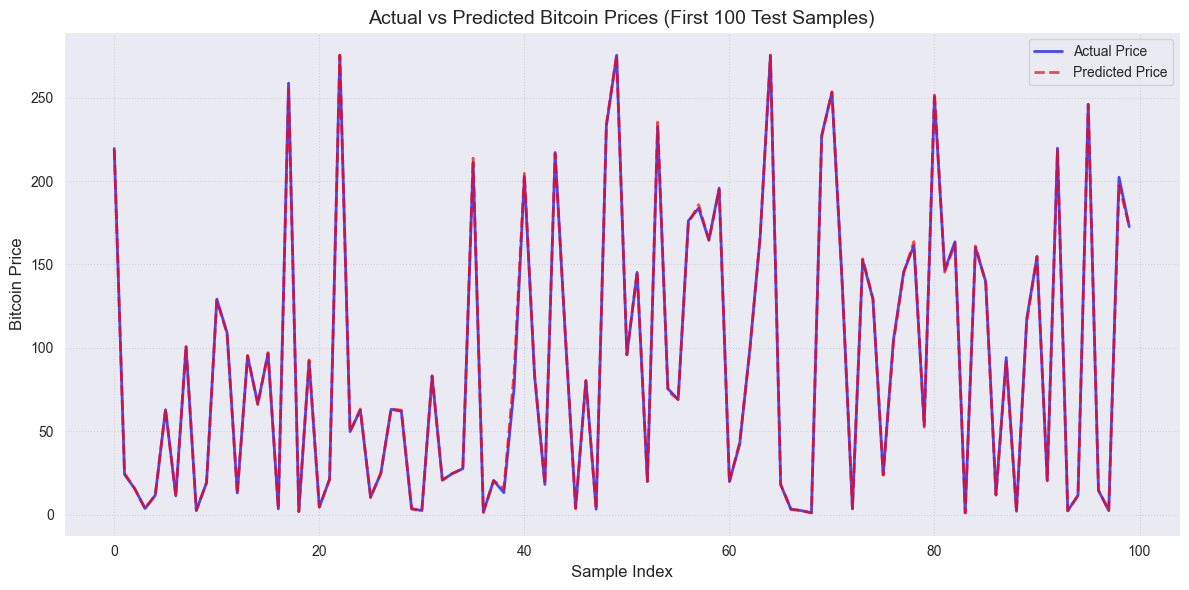

If the lines closely overlap, your model is accurate!


In [30]:
# 2. Visual Comparison: Actual vs Predicted
plt.figure(figsize=(12, 6))

# Plot first 100 predictions for visibility
n_points = min(100, len(y_test))
indices = range(n_points)

plt.plot(indices, y_test.iloc[:n_points].values, 'b-', label='Actual Price', linewidth=2, alpha=0.7)
plt.plot(indices, y_pred_test[:n_points], 'r--', label='Predicted Price', linewidth=2, alpha=0.7)

plt.xlabel('Sample Index', fontsize=12)
plt.ylabel('Bitcoin Price', fontsize=12)
plt.title('Actual vs Predicted Bitcoin Prices (First 100 Test Samples)', fontsize=14)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"If the lines closely overlap, your model is accurate!")

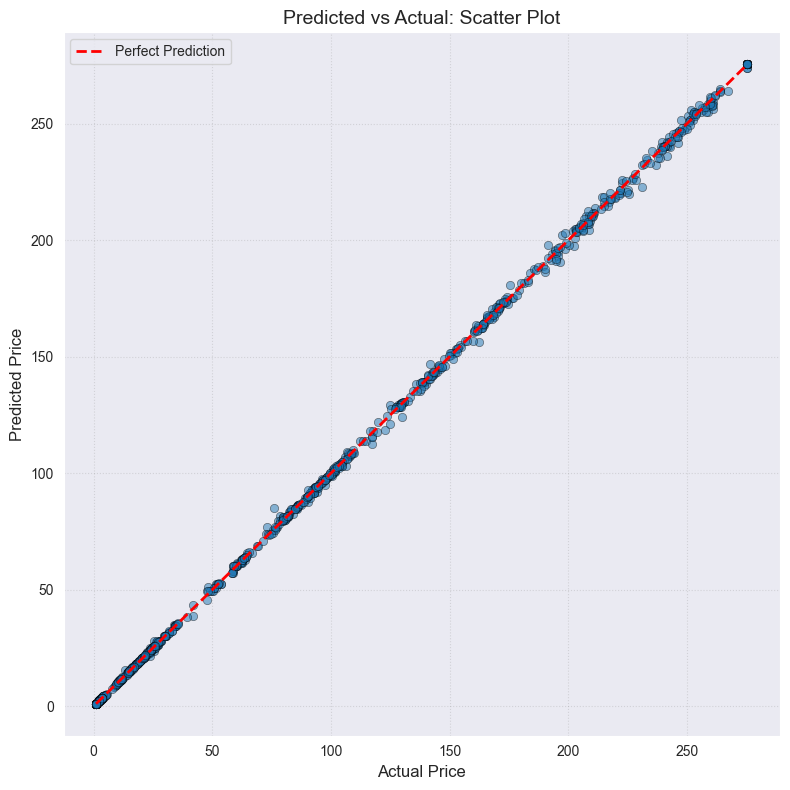

Points closer to the red line = more accurate predictions


In [31]:
# 3. Scatter Plot: Perfect Predictions Should Fall on Diagonal Line
plt.figure(figsize=(8, 8))

plt.scatter(y_test, y_pred_test, alpha=0.5, edgecolors='k', linewidth=0.5)

# Plot perfect prediction line (45-degree line)
min_val = min(y_test.min(), y_pred_test.min())
max_val = max(y_test.max(), y_pred_test.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Prediction')

plt.xlabel('Actual Price', fontsize=12)
plt.ylabel('Predicted Price', fontsize=12)
plt.title('Predicted vs Actual: Scatter Plot', fontsize=14)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Points closer to the red line = more accurate predictions")

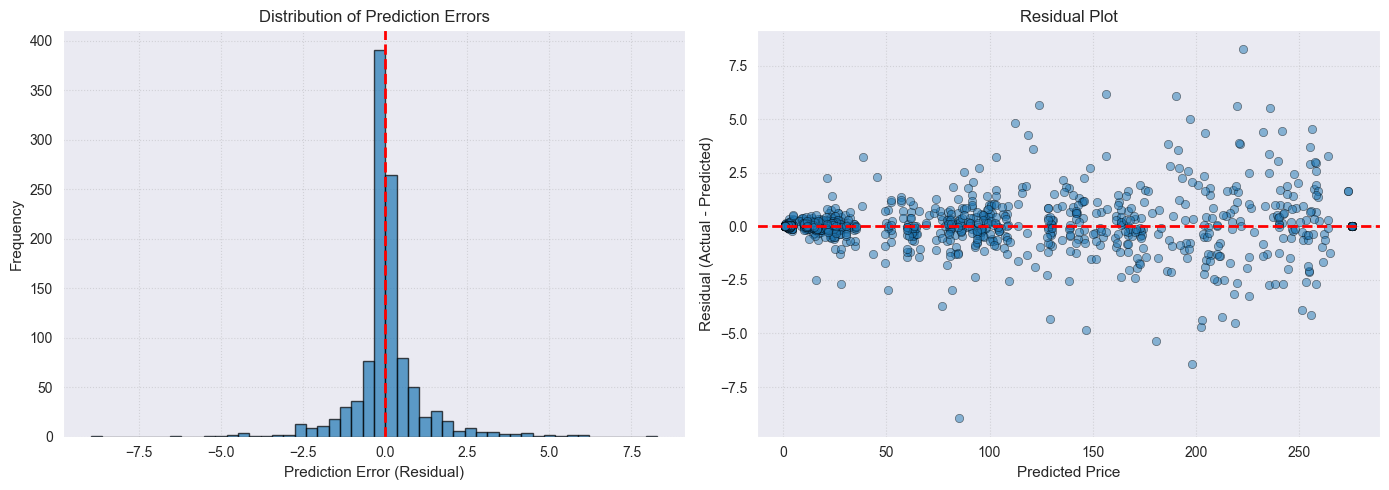

Good model characteristics:
- Residuals centered around 0
- Random scatter (no clear pattern)
- Normal distribution shape


In [32]:
# 4. Residual Analysis: Check Prediction Errors
residuals = y_test - y_pred_test

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram of residuals
axes[0].hist(residuals, bins=50, edgecolor='black', alpha=0.7)
axes[0].axvline(x=0, color='r', linestyle='--', linewidth=2)
axes[0].set_xlabel('Prediction Error (Residual)', fontsize=11)
axes[0].set_ylabel('Frequency', fontsize=11)
axes[0].set_title('Distribution of Prediction Errors', fontsize=12)
axes[0].grid(True, alpha=0.3)

# Residual plot
axes[1].scatter(y_pred_test, residuals, alpha=0.5, edgecolors='k', linewidth=0.5)
axes[1].axhline(y=0, color='r', linestyle='--', linewidth=2)
axes[1].set_xlabel('Predicted Price', fontsize=11)
axes[1].set_ylabel('Residual (Actual - Predicted)', fontsize=11)
axes[1].set_title('Residual Plot', fontsize=12)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Good model characteristics:")
print("- Residuals centered around 0")
print("- Random scatter (no clear pattern)")
print("- Normal distribution shape")

In [33]:
# 5. Detailed Sample-by-Sample Comparison
print("\n" + "="*70)
print("SAMPLE PREDICTIONS vs ACTUAL VALUES")
print("="*70)
print(f"{'Index':<8} {'Actual':<15} {'Predicted':<15} {'Error':<15} {'% Error':<10}")
print("-"*70)

for i in range(min(20, len(y_test))):
    actual = y_test.iloc[i]
    predicted = y_pred_test[i]
    error = actual - predicted
    pct_error = abs(error / actual * 100)
    
    print(f"{i:<8} ${actual:<14.4f} ${predicted:<14.4f} ${error:<14.4f} {pct_error:<9.2f}%")

print("="*70)


SAMPLE PREDICTIONS vs ACTUAL VALUES
Index    Actual          Predicted       Error           % Error   
----------------------------------------------------------------------
0        $219.5067       $218.6858       $0.8209         0.37     %
1        $24.1377        $24.7509        $-0.6132        2.54     %
2        $15.4968        $15.4518        $0.0450         0.29     %
3        $3.6878         $3.6574         $0.0304         0.82     %
4        $11.6190        $11.7250        $-0.1060        0.91     %
5        $62.9163        $63.3376        $-0.4213        0.67     %
6        $11.2872        $11.0993        $0.1879         1.66     %
7        $100.7125       $101.3215       $-0.6090        0.60     %
8        $2.4658         $2.5125         $-0.0467        1.90     %
9        $19.1141        $19.2070        $-0.0928        0.49     %
10       $129.2176       $128.3536       $0.8640         0.67     %
11       $109.1705       $108.5975       $0.5730         0.52     %
12      

## 🎯 Accuracy Checklist

**Your model is likely accurate if:**
- ✅ R² score > 0.7
- ✅ MAPE (Mean Absolute % Error) < 10%
- ✅ Actual vs Predicted lines overlap closely
- ✅ Scatter plot points cluster tightly around diagonal
- ✅ Residuals are randomly scattered around zero
- ✅ No clear patterns in residual plot

**Red flags indicating poor accuracy:**
- ❌ R² score < 0.5
- ❌ MAPE > 20%
- ❌ Large gaps between actual and predicted lines
- ❌ Systematic patterns in residuals (curve, funnel shape)
- ❌ Predictions consistently too high or too low